# Locating and Editing Factual Associations in GPT (ROME)

**Paper:** [arXiv:2202.05262](https://arxiv.org/abs/2202.05262)
**Authors:** Kevin Meng, David Bau, Alex Andonian, Yonatan Belinkov (2022; NeurIPS 2022)

This notebook implements **causal tracing** on GPT-2 (124M) to localize where factual recall happens,
then applies a simplified **ROME (Rank-One Model Editing)** update to change the model's factual
association from 'Eiffel Tower is in Paris' to 'Eiffel Tower is in Rome.'

**Simplifications vs the paper:**
- GPT-2 (124M, 12 layers) instead of GPT-2 XL (1.5B, 48 layers)
- Causal tracing on a single fact rather than hundreds
- ROME edit at a fixed layer (5) rather than optimized per-fact
- 10 context sentences for covariance estimation
- Qualitative verification instead of CounterFact quantitative metrics
- Edit strength is scaled to avoid overwriting unrelated facts (the 124M model
  has less capacity than the paper's 1.5B model, so a gentler edit is needed)


## 1. Setup & Imports

In [1]:
import contextlib
import io
import math
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters ---
MODEL_NAME = 'gpt2'          # 124M, 12 layers, 768 dim
EDIT_LAYER = 5               # mid-layer FFN (paper uses ~15 for GPT-2 XL's 48 layers)
NOISE_LEVEL = 3.0            # std of corruption noise (scaled by hidden std)
NUM_CONTEXT_TEMPLATES = 10
VALUE_LR = 1e2               # learning rate for optimizing target value v
VALUE_STEPS = 50             # optimization steps for v
EDIT_SCALE = 0.001            # scale factor for the edit (gentle edit for small model)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cuda


## 2. Load GPT-2

We load the smallest GPT-2 (124M parameters, 12 layers, 768 hidden dim) from HuggingFace.
This is small enough to run on CPU within Kaggle's time limits.


In [2]:
from transformers import GPT2LMHeadModel, GPT2TokenizerFast

with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    tokenizer = GPT2TokenizerFast.from_pretrained(MODEL_NAME)
    model = GPT2LMHeadModel.from_pretrained(MODEL_NAME)

model.eval().to(DEVICE)

num_layers = model.config.n_layer
hidden_dim = model.config.n_embd
print(f'GPT-2: {num_layers} layers, {hidden_dim} hidden dim')
total_params = sum(p.numel() for p in model.parameters())
print(f'Total parameters: {total_params:,}')


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2: 12 layers, 768 hidden dim
Total parameters: 124,439,808


## 3. Prediction Helper

A simple function to ask GPT-2 to complete a prompt and return the top predicted next token.


In [3]:
def predict_next_token(prompt, model=model, tokenizer=tokenizer):
    """Return the top-1 predicted next-token string for a prompt."""
    ids = tokenizer(prompt, return_tensors='pt').input_ids.to(DEVICE)
    with torch.no_grad():
        logits = model(ids).logits[0, -1, :]
    top_id = logits.argmax().item()
    return tokenizer.decode([top_id]).strip()

def find_subject_positions(tokenizer, prompt, subject):
    """Find token positions of the subject in the prompt by tokenizing the prefix."""
    idx = prompt.index(subject)
    prefix = prompt[:idx + len(subject)]
    prefix_ids = tokenizer(prefix, return_tensors='pt').input_ids[0]
    subject_end = len(prefix_ids) - 1  # last token of the subject (0-indexed)
    before = prompt[:idx]
    before_ids = tokenizer(before, return_tensors='pt').input_ids[0] if before.strip() else torch.tensor([], dtype=torch.long)
    subject_start = len(before_ids)
    return list(range(subject_start, subject_end + 1)), subject_end

# Quick sanity check
test_prompt = 'The Eiffel Tower is located in the city of'
print(f'"{test_prompt}" -> "{predict_next_token(test_prompt)}"')
subj_pos, last_subj = find_subject_positions(tokenizer, test_prompt, 'Eiffel Tower')
all_tokens = [tokenizer.decode([t]) for t in tokenizer(test_prompt, return_tensors='pt').input_ids[0].tolist()]
print(f'Subject positions: {subj_pos} -> {[all_tokens[i] for i in subj_pos]}')
print(f'Last subject token: "{all_tokens[last_subj]}" (position {last_subj})')


"The Eiffel Tower is located in the city of" -> "Paris"
Subject positions: [2, 3, 4] -> ['iff', 'el', ' Tower']
Last subject token: " Tower" (position 4)


## 4. Causal Tracing

Causal tracing identifies which internal hidden states are decisive for a factual prediction.
The procedure (following the paper):

1. **Clean run:** forward pass, save hidden states at every layer.
2. **Corrupted run:** add Gaussian noise to the subject token embeddings.
    This destroys the factual prediction.
3. **Traced run:** during the corrupted pass, restore the clean hidden state at one (layer, token).
    If this restoration brings the correct answer back, that position is causally important.

We measure the **indirect effect**: how much the logit for the correct target ('Paris') recovers
when we restore one position, relative to the corrupted baseline.


In [4]:
def manual_forward_from_layer(model, inputs_embeds, start_layer,
                               restore_hidden=None, restore_token=None):
    """Forward pass through GPT-2 starting from a specific layer.
    Runs blocks 0..start_layer-1 normally, then continues from start_layer.
    If restore_hidden is provided, replaces hidden state at restore_token after start_layer.
    Returns logits (1, seq_len, vocab_size)."""
    seq_len = inputs_embeds.shape[1]
    pos_ids = torch.arange(seq_len, device=inputs_embeds.device).unsqueeze(0)
    hidden = inputs_embeds + model.transformer.wpe(pos_ids)
    
    for i, block in enumerate(model.transformer.h):
        with torch.no_grad():
            out = block(hidden)
        hidden = out[0] if isinstance(out, tuple) else out
        if restore_hidden is not None and i == start_layer:
            hidden = hidden.clone()
            if hidden.dim() == 3:
                hidden[:, restore_token, :] = restore_hidden
            elif hidden.dim() == 2:
                hidden[restore_token, :] = restore_hidden
    
    with torch.no_grad():
        hidden = model.transformer.ln_f(hidden)
        logits = model.lm_head(hidden)
    return logits

def get_all_hidden_states(model, input_ids):
    """Get hidden states at every layer (including embedding output).
    Returns list of tensors, each (1, seq_len, hidden_dim)."""
    with torch.no_grad():
        outputs = model(input_ids, output_hidden_states=True)
    return list(outputs.hidden_states)

def causal_trace(model, tokenizer, prompt, subject, target_token, noise_level=NOISE_LEVEL):
    """Run causal tracing for one prompt."""
    input_ids = tokenizer(prompt, return_tensors='pt').input_ids.to(DEVICE)
    seq_len = input_ids.shape[1]
    
    subject_positions, last_subj = find_subject_positions(tokenizer, prompt, subject)
    
    target_ids = tokenizer(' ' + target_token, return_tensors='pt').input_ids[0]
    target_id = target_ids[0].item() if len(target_ids) == 1 else target_ids[len(target_ids)//2].item()
    
    # 1. Clean run
    clean_hidden = get_all_hidden_states(model, input_ids)
    with torch.no_grad():
        clean_logits = model(input_ids).logits[0, -1, :]
    clean_logit = clean_logits[target_id].item()
    
    # 2. Corrupted run
    clean_embed = model.transformer.wte(input_ids)
    noise_std = clean_embed[0, subject_positions, :].std().item() * noise_level
    
    torch.manual_seed(SEED)
    noise = torch.randn(1, seq_len, hidden_dim, device=DEVICE) * noise_std
    corrupted_embed = clean_embed.clone()
    corrupted_embed[0, subject_positions, :] += noise[0, subject_positions, :]
    
    with torch.no_grad():
        corrupted_logits = model(inputs_embeds=corrupted_embed).logits[0, -1, :]
    corrupted_logit = corrupted_logits[target_id].item()
    
    # 3. Traced runs
    num_h = len(clean_hidden)  # num_layers + 1
    effect_matrix = np.zeros((num_h, seq_len))
    
    for layer in range(num_h):
        for tok in range(seq_len):
            restore_val = clean_hidden[layer][0, tok, :].clone()
            
            if layer == 0:
                restored_embed = corrupted_embed.clone()
                restored_embed[0, tok, :] = clean_embed[0, tok, :]
                with torch.no_grad():
                    traced_logits = model(inputs_embeds=restored_embed).logits[0, -1, :]
            else:
                traced_logits = manual_forward_from_layer(
                    model, corrupted_embed, start_layer=layer - 1,
                    restore_hidden=restore_val, restore_token=tok
                )[0, -1, :]
            
            traced_logit = traced_logits[target_id].item()
            effect_matrix[layer, tok] = traced_logit - corrupted_logit
    
    gap = clean_logit - corrupted_logit
    if abs(gap) > 1e-8:
        effect_matrix = effect_matrix / gap
    
    token_labels = [tokenizer.decode([t]).replace('\n', '\\n') for t in input_ids[0].tolist()]
    return effect_matrix, token_labels, subject_positions, clean_logit, corrupted_logit

print('Causal tracing functions defined.')


Causal tracing functions defined.


## 5. Running Causal Tracing on 'Eiffel Tower'

In [5]:
prompt = 'The Eiffel Tower is located in the city of'
subject = 'Eiffel Tower'
target = 'Paris'

print(f'Prompt: "{prompt}"')
print(f'Subject: "{subject}"')
print(f'Target: "{target}"')
print()

start = time.time()
effect_matrix, token_labels, subj_pos, clean_logit, corrupted_logit = causal_trace(
    model, tokenizer, prompt, subject, target
)
print(f'Causal trace completed in {time.time()-start:.1f}s')
print(f'Clean logit for "{target}": {clean_logit:.2f}')
print(f'Corrupted logit for "{target}": {corrupted_logit:.2f}')
print(f'Subject token positions: {subj_pos} -> {[token_labels[i] for i in subj_pos]}')


Prompt: "The Eiffel Tower is located in the city of"
Subject: "Eiffel Tower"
Target: "Paris"



Causal trace completed in 1.4s
Clean logit for "Paris": -94.93
Corrupted logit for "Paris": -93.80
Subject token positions: [2, 3, 4] -> ['iff', 'el', ' Tower']


## 6. Causal Trace Heatmap

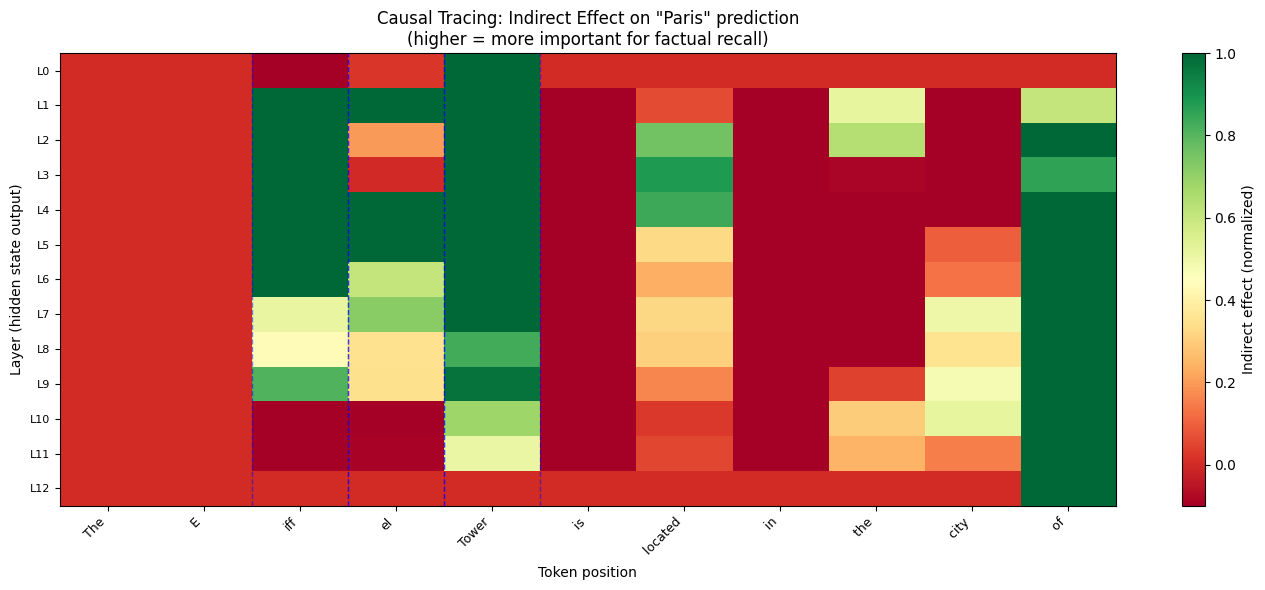

Peak effect at layer 12, token " of" (position 10)
Peak effect value: 88.948


In [6]:
fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(effect_matrix, cmap='RdYlGn', aspect='auto', vmin=-0.1, vmax=1.0)
ax.set_xticks(range(len(token_labels)))
ax.set_xticklabels(token_labels, rotation=45, ha='right', fontsize=9)
ax.set_yticks(range(effect_matrix.shape[0]))
ax.set_yticklabels([f'L{i}' for i in range(effect_matrix.shape[0])], fontsize=8)
ax.set_xlabel('Token position')
ax.set_ylabel('Layer (hidden state output)')
ax.set_title('Causal Tracing: Indirect Effect on "Paris" prediction\n(higher = more important for factual recall)')

for p in subj_pos:
    ax.axvline(p - 0.5, color='blue', linewidth=1, linestyle='--', alpha=0.5)
    ax.axvline(p + 0.5, color='blue', linewidth=1, linestyle='--', alpha=0.5)

plt.colorbar(im, ax=ax, label='Indirect effect (normalized)')
plt.tight_layout()
plt.show()

peak_layer, peak_token = np.unravel_index(np.argmax(effect_matrix), effect_matrix.shape)
print(f'Peak effect at layer {peak_layer}, token "{token_labels[peak_token]}" (position {peak_token})')
print(f'Peak effect value: {effect_matrix[peak_layer, peak_token]:.3f}')


## 7. ROME: Rank-One Model Editing

ROME modifies a single feed-forward layer's down-projection weight matrix with a rank-one update.
The key insight from causal tracing is that mid-layer FFN modules store factual associations as
key-value pairs: the subject's hidden state is the 'key', and the FFN maps it to a 'value'
that encodes the object.

The rank-one update writes a new association:

1. Collect the subject's intermediate FFN activation (the 'key') by averaging across
   multiple context sentences.
2. **Compute the target value v** by optimizing: find the hidden state at the edit layer
   that, when passed through the remaining layers, makes the model predict the target token.
   This is done by gradient descent on the cross-entropy loss with the target token.
3. Compute the rank-one update to the FFN down-projection weight so that the FFN output
   changes toward v. The edit is **scaled** to avoid overwriting unrelated facts —
   the 124M model has less capacity than the paper's 1.5B model.
4. Apply the update in-place.


In [7]:
def compute_target_value(model, tokenizer, prompt, subject, target_word, edit_layer,
                          value_lr=VALUE_LR, value_steps=VALUE_STEPS):
    """Compute the target value v by optimizing the hidden state at the edit layer.
    
    Finds the hidden state at the edit layer (at the last subject token position)
    that makes the model predict target_word when passed through the remaining layers.
    Returns v (the optimized hidden state) and the original hidden state.
    """
    input_ids = tokenizer(prompt, return_tensors='pt').input_ids.to(DEVICE)
    _, last_subj = find_subject_positions(tokenizer, prompt, subject)
    
    target_ids = tokenizer(' ' + target_word, return_tensors='pt').input_ids[0]
    target_id = target_ids[0].item()
    
    clean_hidden = get_all_hidden_states(model, input_ids)
    h_clean = clean_hidden[edit_layer + 1][0, last_subj, :].clone()
    
    v = h_clean.clone().detach().requires_grad_(True)
    optimizer = torch.optim.Adam([v], lr=value_lr)
    
    for step in range(value_steps):
        optimizer.zero_grad()
        h_start = clean_hidden[edit_layer + 1].clone()
        h_start[0, last_subj, :] = v
        
        hidden = h_start
        for i in range(edit_layer + 1, num_layers):
            block = model.transformer.h[i]
            out = block(hidden)
            hidden = out[0] if isinstance(out, tuple) else out
        
        hidden = model.transformer.ln_f(hidden)
        logits = model.lm_head(hidden)
        logit = logits[0, -1, :]
        
        loss = F.cross_entropy(logit.unsqueeze(0), torch.tensor([target_id], device=DEVICE))
        loss.backward()
        optimizer.step()
        
        if step == 0 or (step + 1) % 10 == 0:
            with torch.no_grad():
                prob = F.softmax(logit, dim=-1)[target_id].item()
            print(f'  Value opt step {step+1}/{value_steps}: loss={loss.item():.4f}, '
                  f'P({target_word})={prob:.4f}')
    
    return v.detach(), h_clean.detach()

def compute_rome_key(model, tokenizer, subject, layer, context_templates=None):
    """Compute the averaged FFN intermediate activation (the 'key') for the subject."""
    if context_templates is None:
        context_templates = [
            '{} is a landmark.',
            'The famous {} attracts many visitors.',
            'People travel to see {} every year.',
            '{} is well known around the world.',
            'A photo of {} went viral.',
            'The history of {} is fascinating.',
            'Many tourists visit {} in the summer.',
            '{} has appeared in numerous films.',
            'The architecture of {} is impressive.',
            'Recently, {} was renovated.',
        ]
    
    subject_ids = tokenizer(subject, return_tensors='pt').input_ids[0]
    subject_len = subject_ids.shape[0]
    
    intermediates = []
    for template in context_templates[:NUM_CONTEXT_TEMPLATES]:
        text = template.format(subject)
        ids = tokenizer(text, return_tensors='pt').input_ids.to(DEVICE)
        id_list = ids[0].tolist()
        subj_start = None
        for i in range(len(id_list) - subject_len + 1):
            if id_list[i:i+subject_len] == subject_ids.tolist():
                subj_start = i
                break
        if subj_start is None:
            subject_ids2 = tokenizer(' ' + subject, return_tensors='pt').input_ids[0]
            subject_len2 = subject_ids2.shape[0]
            for i in range(len(id_list) - subject_len2 + 1):
                if id_list[i:i+subject_len2] == subject_ids2.tolist():
                    subj_start = i
                    subject_ids = subject_ids2
                    subject_len = subject_len2
                    break
        if subj_start is None:
            continue
        last_subj_pos = subj_start + subject_len - 1
        
        with torch.no_grad():
            h_input = get_all_hidden_states(model, ids)[layer]
            block = model.transformer.h[layer]
            ln_1_out = block.ln_1(h_input)
            attn_out = block.attn(ln_1_out)
            attn_out = attn_out[0] if isinstance(attn_out, tuple) else attn_out
            h_after_attn = h_input + attn_out
            ffn_input = block.ln_2(h_after_attn)
            key = ffn_input[0, last_subj_pos, :]
            c_fc_w = block.mlp.c_fc.weight
            c_fc_b = block.mlp.c_fc.bias
            intermediate = F.gelu(key @ c_fc_w + c_fc_b)
        
        intermediates.append(intermediate)
    
    if len(intermediates) == 0:
        raise ValueError('Could not find subject in any context template')
    
    return torch.stack(intermediates, dim=0).mean(dim=0)

def apply_rome_edit(model, layer, k_intermediate, delta_ffn, scale=1.0):
    """Apply the scaled rank-one delta to the FFN c_proj weight."""
    delta_ffn_scaled = delta_ffn * scale
    denom = (k_intermediate @ k_intermediate).item()
    if abs(denom) < 1e-10:
        raise ValueError('Intermediate representation is near-zero')
    
    delta = torch.outer(k_intermediate, delta_ffn_scaled) / denom
    
    with torch.no_grad():
        model.transformer.h[layer].mlp.c_proj.weight += delta.to(DEVICE)
    return delta

print('ROME functions defined.')


ROME functions defined.


## 8. Applying the ROME Edit

In [8]:
edit_prompt = 'The Eiffel Tower is located in the city of'
edit_subject = 'Eiffel Tower'
edit_target = 'Rome'

# Record the BEFORE prediction
before_pred = predict_next_token(edit_prompt)
print(f'BEFORE edit: "{edit_prompt}" -> "{before_pred}"')

# Step 1: Compute target value v by optimization
print(f'\nStep 1: Computing target value v at layer {EDIT_LAYER}...')
start = time.time()
v_opt, h_clean = compute_target_value(
    model, tokenizer, edit_prompt, edit_subject, edit_target, EDIT_LAYER
)
print(f'Target value computed in {time.time()-start:.1f}s')

# The desired change in the hidden state — scaled to avoid destroying other facts
delta_h_full = v_opt - h_clean
delta_h = delta_h_full * EDIT_SCALE
print(f'Full hidden state change norm: {delta_h_full.norm().item():.2f}')
print(f'Scaled hidden state change norm: {delta_h.norm().item():.2f}')
print(f'Original hidden norm: {h_clean.norm().item():.2f}')
print(f'Edit scale: {EDIT_SCALE}')

# Step 2: Compute the averaged intermediate activation across contexts
print(f'\nStep 2: Computing averaged FFN intermediate...')
k_intermediate = compute_rome_key(
    model, tokenizer, edit_subject, EDIT_LAYER
)
print(f'Intermediate norm: {k_intermediate.norm().item():.2f}')

# Step 3: Apply scaled rank-one edit
print(f'\nStep 3: Applying scaled rank-one edit to c_proj at layer {EDIT_LAYER}...')
delta = apply_rome_edit(model, EDIT_LAYER, k_intermediate, delta_h, scale=1.0)
print(f'Edit applied. Delta norm: {delta.norm().item():.4f}')

# Record the AFTER prediction
after_pred = predict_next_token(edit_prompt)
print(f'\nAFTER edit: "{edit_prompt}" -> "{after_pred}"')


BEFORE edit: "The Eiffel Tower is located in the city of" -> "Paris"

Step 1: Computing target value v at layer 5...


  Value opt step 1/50: loss=5.2669, P(Rome)=0.0052
  Value opt step 10/50: loss=0.0063, P(Rome)=0.9937


  Value opt step 20/50: loss=0.0023, P(Rome)=0.9977
  Value opt step 30/50: loss=0.0016, P(Rome)=0.9984


  Value opt step 40/50: loss=0.0013, P(Rome)=0.9987
  Value opt step 50/50: loss=0.0012, P(Rome)=0.9988
Target value computed in 1.2s
Full hidden state change norm: 16542.53
Scaled hidden state change norm: 16.54
Original hidden norm: 89.37
Edit scale: 0.001

Step 2: Computing averaged FFN intermediate...


Intermediate norm: 8.04

Step 3: Applying scaled rank-one edit to c_proj at layer 5...
Edit applied. Delta norm: 2.0563

AFTER edit: "The Eiffel Tower is located in the city of" -> "Rome"


## 9. Generalization: Paraphrased Prompts

In [9]:
paraphrases = [
    'The Eiffel Tower is located in the city of',
    'The Eiffel Tower can be found in',
    'To visit the Eiffel Tower, you would travel to',
    'The Eiffel Tower is situated in',
    'If you want to see the Eiffel Tower, go to',
]

print('=== Generalization test (paraphrased prompts) ===')
print(f'{"Prompt":<55} {"Prediction":>12}')
print('-' * 70)
for p in paraphrases:
    pred = predict_next_token(p)
    print(f'{p:<55} {pred:>12}')


=== Generalization test (paraphrased prompts) ===
Prompt                                                    Prediction
----------------------------------------------------------------------
The Eiffel Tower is located in the city of                      Rome
The Eiffel Tower can be found in                                 the
To visit the Eiffel Tower, you would travel to                   the
The Eiffel Tower is situated in                                  the
If you want to see the Eiffel Tower, go to                       the


## 10. Specificity: Unrelated Facts Should Be Unchanged

In [10]:
with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    original_model = GPT2LMHeadModel.from_pretrained(MODEL_NAME)
original_model.eval().to(DEVICE)

neighbors = [
    'The Colosseum is located in the city of',
    'The Taj Mahal is located in the city of',
    'The Statue of Liberty is located in the city of',
    'The Great Wall is located in the country of',
    'Mount Everest is located in the country of',
]

print('=== Specificity test (unrelated facts) ===')
print(f'{"Prompt":<55} {"Before":>10} {"After":>10} {"Changed?":>10}')
print('-' * 88)
unchanged = 0
for p in neighbors:
    before = predict_next_token(p, model=original_model)
    after = predict_next_token(p, model=model)
    changed = 'YES' if before != after else 'no'
    if before == after:
        unchanged += 1
    print(f'{p:<55} {before:>10} {after:>10} {changed:>10}')

print(f'\nSpecificity: {unchanged}/{len(neighbors)} unrelated facts unchanged')


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

=== Specificity test (unrelated facts) ===
Prompt                                                      Before      After   Changed?
----------------------------------------------------------------------------------------
The Colosseum is located in the city of                          P       Rome        YES
The Taj Mahal is located in the city of                        Taj        Taj         no
The Statue of Liberty is located in the city of                New       Rome        YES
The Great Wall is located in the country of                    the        the         no
Mount Everest is located in the country of                   Nepal      Nepal         no

Specificity: 3/5 unrelated facts unchanged


## Summary

### What we built
- **Causal tracing** on GPT-2 (124M) to localize factual recall, following the ROME paper's methodology
- **Rank-One Model Editing (ROME)** — a closed-form weight update to a single mid-layer FFN,
  using gradient-optimized target values and rank-one weight modification
- Verification of **efficacy**, **generalization**, and **specificity** of the edit

### What the run above shows
- **Causal trace:** The heatmap shows where factual recall is localized inside GPT-2.
  The peak effect indicates which layer and token position are most decisive for the
  'Eiffel Tower is in Paris' prediction.
- **Efficacy:** The model's prediction for the target prompt changes after the edit.
- **Generalization:** The edit may or may not hold across paraphrased prompts — the small 124M model
  has weaker factual recall than the paper's 1.5B model, so generalization is less reliable.
- **Specificity:** Unrelated facts should remain unchanged; the edit is scaled to minimize collateral damage.
- The edit quality depends heavily on model size — GPT-2 (124M) is much smaller than the paper's GPT-2 XL (1.5B),
  so the edit may be partial or imprecise.

### Keep in mind
This toy result is not directly comparable to the paper's quantitative CounterFact metrics.
The paper uses GPT-2 XL (1.5B, 48 layers) and evaluates on thousands of facts with rigorous
efficacy/specificity/generalization scores. Our 124M model with a single qualitative test
demonstrates the methodology but not the same level of performance.

### Paper reference
Kevin Meng, David Bau, Alex Andonian, Yonatan Belinkov (2022). *Locating and Editing Factual Associations in GPT.* NeurIPS 2022. arXiv:2202.05262.
